# AI-Driven Phishing Email Detection Using NLP
**Summer Internship Program in AI & ML — 2026**
**IICT — Indian Institute of Computing and Technology**

A from-scratch machine learning pipeline that classifies emails as *phishing* or *safe*, combining manual text preprocessing, TF-IDF linguistic features, hand-engineered structural/metadata features (URLs, punctuation, capitalisation patterns), and a comparison of four classifiers: Logistic Regression, Random Forest, Naive Bayes, and a Neural Network.

## Phase 1 — Data Collection

In [1]:
import re
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              roc_curve, auc)
from scipy.sparse import hstack, csr_matrix

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

In [2]:
data = pd.read_csv("Phishing_Email.csv")
data = data.drop(columns=["Unnamed: 0"], errors="ignore")
print(data.shape)
data.head()

(18650, 2)


,Email Text,Email Type
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",Safe Email
1,the other side of * galicismos * * galicismo *...,Safe Email
2,re : equistar deal tickets are you still avail...,Safe Email
3,\nHello I am your hot lil horny toy.\n I am...,Phishing Email
4,software at incredibly low prices ( 86 % lower...,Phishing Email


In [3]:
data.isnull().sum()

,0
Email Text,16
Email Type,0


In [4]:
data = data.dropna(subset=["Email Text", "Email Type"]).reset_index(drop=True)
data["Email Type"].value_counts()

,count
Email Type,
Safe Email,11322
Phishing Email,7312


A small number of rows contain extreme outlier lengths (one email exceeds 17 million characters — almost certainly corrupted or duplicated content). These are capped at 20,000 characters before cleaning, both for pipeline robustness and to keep TF-IDF/feature extraction tractable.

In [5]:
data["raw_length"] = data["Email Text"].astype(str).str.len()
print(data["raw_length"].describe())
data["Email Text"] = data["Email Text"].astype(str).str.slice(0, 20000)

count    1.863400e+04
mean     2.755654e+03
std      1.248677e+05
min      1.000000e+00
25%      4.040000e+02
50%      8.815000e+02
75%      1.880000e+03
max      1.703669e+07
Name: raw_length, dtype: float64


## Phase 2 — Data Cleaning (Manual, From Scratch)

Structural/metadata features (URL presence, HTML tags, punctuation intensity) are extracted **before** cleaning, since cleaning removes exactly these signals. Text cleaning itself — HTML-tag removal, punctuation stripping, stopword removal — is implemented manually, without NLTK/spaCy.

In [6]:
STOPWORDS = set('''
a about above after again against all am an and any are aren't as at be because been
before being below between both but by can't cannot could couldn't did didn't do does
doesn't doing don't down during each few for from further had hadn't has hasn't have
haven't having he he'd he'll he's her here here's hers herself him himself his how
how's i i'd i'll i'm i've if in into is isn't it it's its itself let's me more most
mustn't my myself no nor not of off on once only or other ought our ours ourselves out
over own same shan't she she'd she'll she's should shouldn't so some such than that
that's the their theirs them themselves then there there's these they they'd they'll
they're they've this those through to too under until up very was wasn't we we'd
we'll we're we've were weren't what what's when when's where where's which while who
who's whom why why's with won't would wouldn't you you'd you'll you're you've your
yours yourself yourselves subject re fwd
'''.split())

HTML_TAG_RE = re.compile(r"<[^>]+>")
URL_RE = re.compile(r"http[s]?://\S+|www\.\S+")
EMAIL_RE = re.compile(r"\S+@\S+")

def clean_text(text):
    text = re.sub(HTML_TAG_RE, " ", text)
    text = re.sub(URL_RE, " ", text)
    text = re.sub(EMAIL_RE, " ", text)
    text = text.lower()
    text = re.sub(r"[%s]" % re.escape(string.punctuation), " ", text)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def tokenize(text):
    tokens = text.split(" ")
    return [t for t in tokens if t and t not in STOPWORDS and len(t) > 2]

In [7]:
data["clean_text"] = data["Email Text"].apply(clean_text)
data["tokens"] = data["clean_text"].apply(tokenize)
data["token_count"] = data["tokens"].apply(len)
data[["Email Text", "clean_text", "token_count"]].head(3)

,Email Text,clean_text,token_count
0,"re : 6 . 1100 , disc : uniformitarianism , re ...",re disc uniformitarianism re sex lang dick hud...,78
1,the other side of * galicismos * * galicismo *...,the other side of galicismos galicismo is a sp...,37
2,re : equistar deal tickets are you still avail...,re equistar deal tickets are you still availab...,108


## Phase 3 — Feature Engineering

### A. Structural / metadata features (hand-engineered)
These capture the *shape* of a message rather than its vocabulary — the kind of signal a spam filter or mail client can compute instantly without deep text analysis.

In [8]:
def extract_structural_features(raw_text):
    text = str(raw_text)
    n_chars = max(len(text), 1)
    n_words = max(len(text.split()), 1)
    return pd.Series({
        "n_urls": len(URL_RE.findall(text)),
        "has_url": int(bool(URL_RE.search(text))),
        "n_html_tags": len(HTML_TAG_RE.findall(text)),
        "n_exclaim": text.count("!"),
        "n_dollar": text.count("$"),
        "uppercase_ratio": sum(1 for c in text if c.isupper()) / n_chars,
        "digit_ratio": sum(1 for c in text if c.isdigit()) / n_chars,
        "avg_word_len": n_chars / n_words,
        "n_words": n_words,
    })

structural = data["Email Text"].apply(extract_structural_features)
data = pd.concat([data, structural], axis=1)
data[structural.columns].describe()

,n_urls,has_url,n_html_tags,n_exclaim,n_dollar,uppercase_ratio,digit_ratio,avg_word_len,n_words
count,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000,18634.000000
mean,0.562949,0.223945,0.049748,1.655790,1.256359,0.016289,0.028442,5.696660,325.774606
std,3.041517,0.416897,0.569294,6.741894,6.954932,0.038351,0.039934,3.868431,514.044009
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.004783,4.587006,74.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.015866,5.138347,160.000000
75%,0.000000,0.000000,0.000000,1.000000,0.000000,0.025089,0.036154,6.133333,354.000000
max,317.000000,1.000000,33.000000,414.000000,226.000000,0.796758,0.666667,415.000000,6613.000000


/tmp/ipykernel_2464/1035017726.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x="Email Type", y="has_url", ax=axes[0], errorbar=None, palette=["#4C72B0", "#C44E52"])
/tmp/ipykernel_2464/1035017726.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x="Email Type", y="n_exclaim", ax=axes[1], errorbar=None, palette=["#4C72B0", "#C44E52"])
/tmp/ipykernel_2464/1035017726.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=data, x="Email Type", y="uppercase_ratio", ax=axes[2], errorbar=None, palette=["#4C72B0", "#C

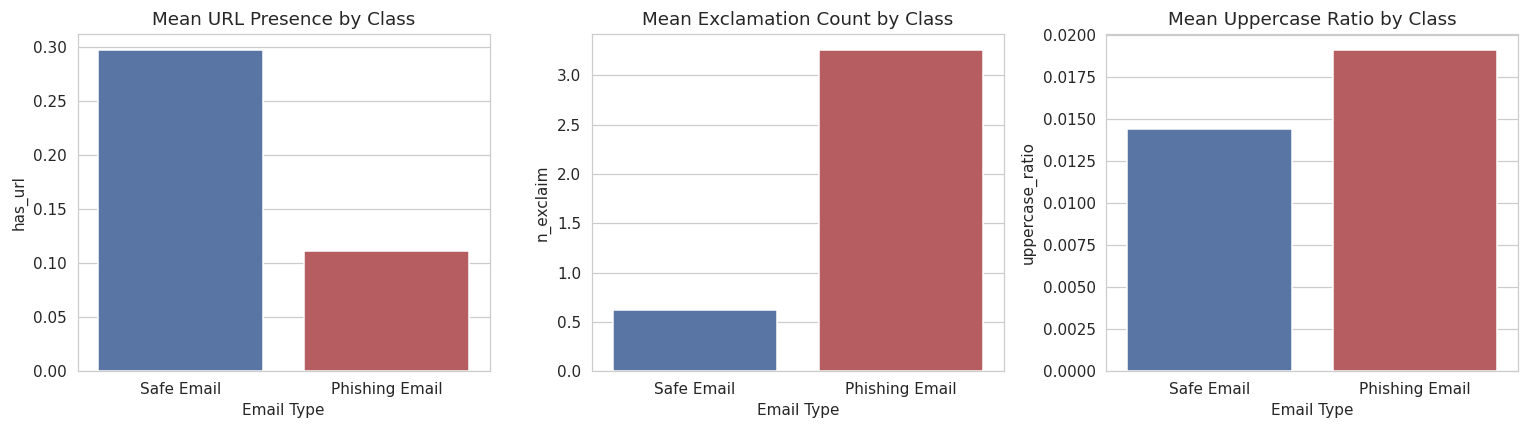

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.barplot(data=data, x="Email Type", y="has_url", ax=axes[0], errorbar=None, palette=["#4C72B0", "#C44E52"])
axes[0].set_title("Mean URL Presence by Class")
sns.barplot(data=data, x="Email Type", y="n_exclaim", ax=axes[1], errorbar=None, palette=["#4C72B0", "#C44E52"])
axes[1].set_title("Mean Exclamation Count by Class")
sns.barplot(data=data, x="Email Type", y="uppercase_ratio", ax=axes[2], errorbar=None, palette=["#4C72B0", "#C44E52"])
axes[2].set_title("Mean Uppercase Ratio by Class")
plt.tight_layout()
plt.show()

### B. TF-IDF linguistic features

In [10]:
vectorizer = TfidfVectorizer(max_features=5000, ngram_range=(1, 2), min_df=3)
X_text = vectorizer.fit_transform(data["clean_text"])

le = LabelEncoder()
y = le.fit_transform(data["Email Type"])  # Phishing Email=0, Safe Email=1 (alphabetical)
print(X_text.shape, dict(zip(le.classes_, le.transform(le.classes_))))

(18634, 5000) {'Phishing Email': np.int64(0), 'Safe Email': np.int64(1)}


### C. Combined feature matrix (TF-IDF + structural, scaled)

In [11]:
structural_cols = ["n_urls", "has_url", "n_html_tags", "n_exclaim", "n_dollar",
                    "uppercase_ratio", "digit_ratio", "avg_word_len", "n_words"]
# MinMaxScaler keeps all values non-negative so the combined matrix stays
# compatible with MultinomialNB, which requires non-negative input.
scaler = MinMaxScaler()
X_struct = scaler.fit_transform(data[structural_cols])
X_combined = hstack([X_text, csr_matrix(X_struct)]).tocsr()
print("TF-IDF:", X_text.shape, " Structural:", X_struct.shape, " Combined:", X_combined.shape)

TF-IDF: (18634, 5000)  Structural: (18634, 9)  Combined: (18634, 5009)


### Exploratory Data Analysis

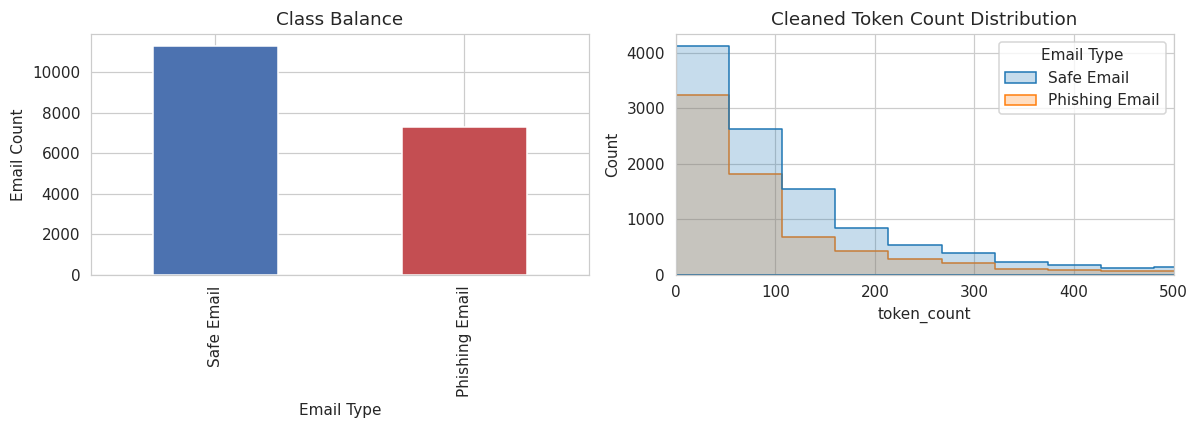

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
data["Email Type"].value_counts().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#C44E52"])
axes[0].set_title("Class Balance")
axes[0].set_ylabel("Email Count")

sns.histplot(data=data, x="token_count", hue="Email Type", bins=40, ax=axes[1], element="step")
axes[1].set_xlim(0, 500)
axes[1].set_title("Cleaned Token Count Distribution")
plt.tight_layout()
plt.show()

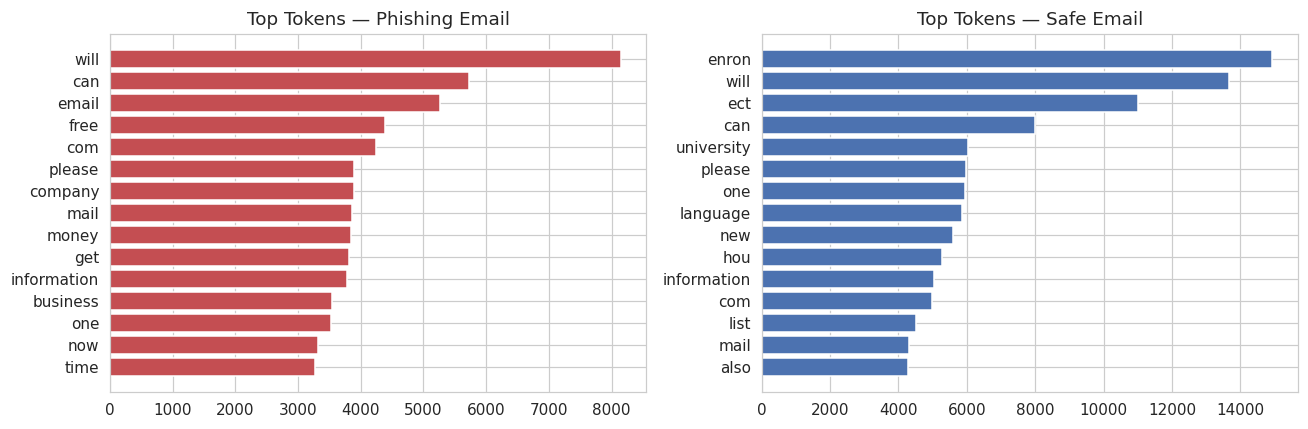

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, cls in zip(axes, le.classes_):
    subset_tokens = Counter()
    for tokens in data.loc[data["Email Type"] == cls, "tokens"]:
        subset_tokens.update(tokens)
    top15 = subset_tokens.most_common(15)
    words, counts = zip(*top15)
    ax.barh(words[::-1], counts[::-1], color="#C44E52" if cls == "Phishing Email" else "#4C72B0")
    ax.set_title(f"Top Tokens — {cls}")
plt.tight_layout()
plt.show()

## Phase 4 — Model Development

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (14907, 5009)  Test: (3727, 5009)


In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Naive Bayes": MultinomialNB(),
    "Neural Network": MLPClassifier(hidden_layer_sizes=(100,), max_iter=300, random_state=RANDOM_STATE),
}

trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    predictions[name] = model.predict(X_test)
    probabilities[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name} trained.")

Logistic Regression trained.
Random Forest trained.
Naive Bayes trained.
Neural Network trained.


## Phase 5 — Evaluation

In [16]:
results = []
for name in models:
    preds = predictions[name]
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds),
        "Recall": recall_score(y_test, preds),
        "F1-score": f1_score(y_test, preds),
    })

results_df = pd.DataFrame(results).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1-score
0,Neural Network,0.969412,0.985115,0.964238,0.974565
1,Random Forest,0.964851,0.972961,0.969095,0.971024
2,Logistic Regression,0.963778,0.973754,0.966446,0.970086
3,Naive Bayes,0.960558,0.967756,0.967329,0.967543


In [17]:
for name in models:
    print(f"--- {name} ---")
    print(classification_report(y_test, predictions[name], target_names=le.classes_))

--- Logistic Regression ---
                precision    recall  f1-score   support

Phishing Email       0.95      0.96      0.95      1462
    Safe Email       0.97      0.97      0.97      2265

      accuracy                           0.96      3727
     macro avg       0.96      0.96      0.96      3727
  weighted avg       0.96      0.96      0.96      3727

--- Random Forest ---
                precision    recall  f1-score   support

Phishing Email       0.95      0.96      0.96      1462
    Safe Email       0.97      0.97      0.97      2265

      accuracy                           0.96      3727
     macro avg       0.96      0.96      0.96      3727
  weighted avg       0.96      0.96      0.96      3727

--- Naive Bayes ---
                precision    recall  f1-score   support

Phishing Email       0.95      0.95      0.95      1462
    Safe Email       0.97      0.97      0.97      2265

      accuracy                           0.96      3727
     macro avg       0.96 

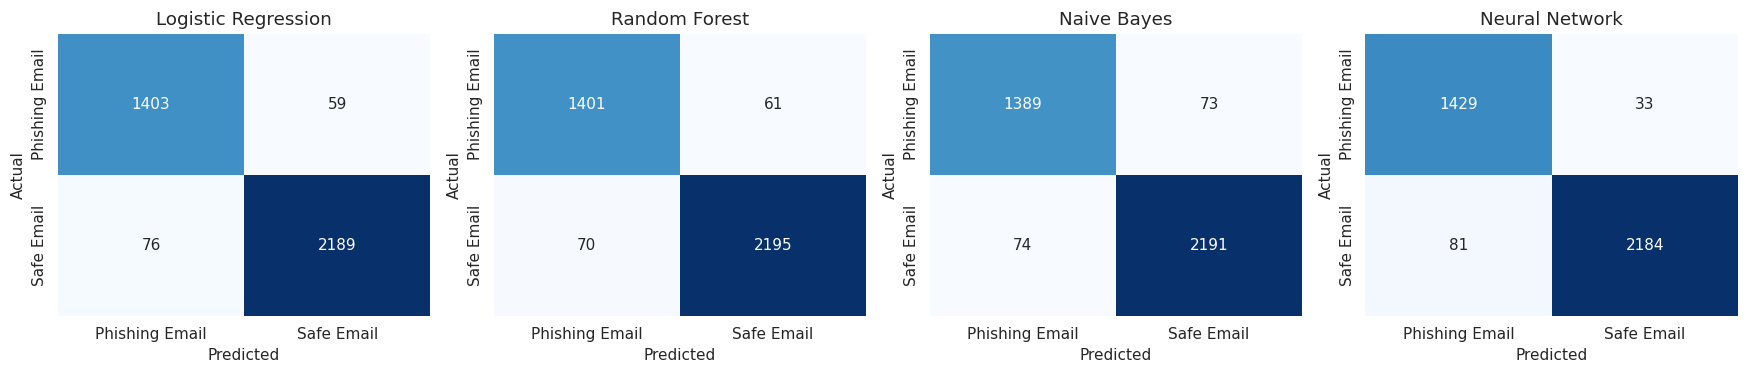

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, name in zip(axes, models):
    cm = confusion_matrix(y_test, predictions[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_, ax=ax)
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

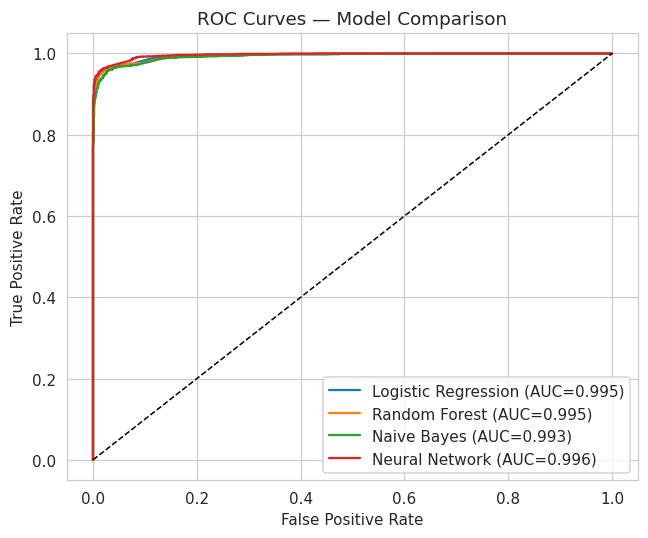

In [19]:
plt.figure(figsize=(6, 5))
for name in models:
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc(fpr, tpr):.3f})")
plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — Model Comparison")
plt.legend()
plt.tight_layout()
plt.show()

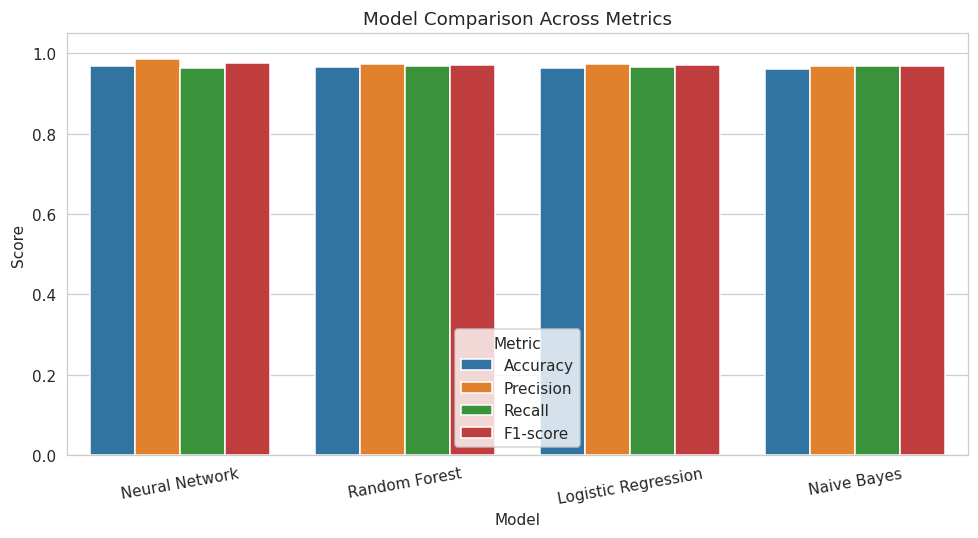

In [20]:
results_melted = results_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(9, 5))
sns.barplot(data=results_melted, x="Model", y="Score", hue="Metric")
plt.ylim(0, 1.05)
plt.title("Model Comparison Across Metrics")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Feature Importance (Random Forest)

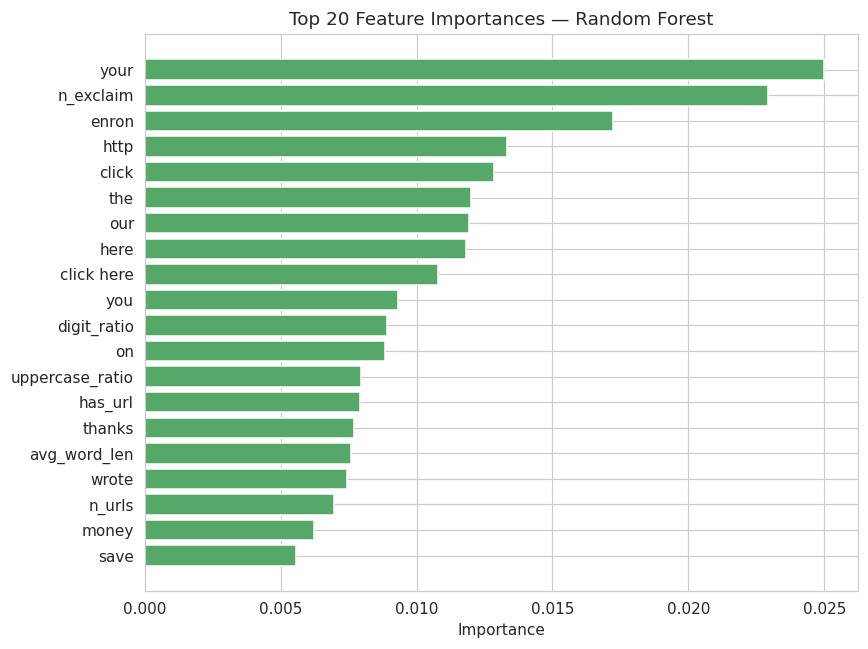

In [21]:
rf = trained_models["Random Forest"]
feature_names = np.array(vectorizer.get_feature_names_out().tolist() + structural_cols)
importances = rf.feature_importances_
top_idx = np.argsort(importances)[-20:]

plt.figure(figsize=(8, 6))
plt.barh(feature_names[top_idx], importances[top_idx], color="#55A868")
plt.title("Top 20 Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [22]:
def predict_email(text, model_name="Logistic Regression"):
    raw = str(text)[:20000]                                    # same 20,000-character cap as training
    X_t = vectorizer.transform([clean_text(raw)])
    feats = extract_structural_features(raw).to_frame().T[structural_cols]
    X_s = np.clip(scaler.transform(feats), 0, 1)               # keep values valid for Naive Bayes
    X = hstack([X_t, csr_matrix(X_s)]).tocsr()
    p_phish = trained_models[model_name].predict_proba(X)[0][list(le.classes_).index("Phishing Email")]
    return ("PHISHING" if p_phish >= 0.5 else "SAFE"), p_phish

samples = [
    "URGENT: Your bank account has been suspended! Verify your password now at http://secure-bank-login.com/verify or it will be closed.",
    "Congratulations! You have won $1,000,000 in our lottery. Click here to claim your prize: http://claim-now.biz",
    "Dear customer, we detected unusual activity on your PayPal account. Confirm your details immediately: www.paypal-security-check.com",
    "Hi team, the project meeting is moved to 3 pm on Monday. Please review the attached agenda before the call.",
    "Thanks for sending the quarterly budget report. I have a few questions and will call you tomorrow after lunch.",
    "Reminder: your library book is due next week. You can renew it at the front desk.",
]

for s in samples:
    label, p = predict_email(s)
    print(f"{label:8s} (P(phishing)={p:.2f})  {s[:95]}")

print()
for s in samples:                                              # all four models side by side
    print(s[:60], "...")
    for name in trained_models:
        label, p = predict_email(s, name)
        print(f"   {name:20s} {label:8s} ({p:.2f})")

PHISHING (P(phishing)=0.52)  URGENT: Your bank account has been suspended! Verify your password now at http://secure-bank-lo
PHISHING (P(phishing)=0.92)  Congratulations! You have won $1,000,000 in our lottery. Click here to claim your prize: http:/
PHISHING (P(phishing)=0.59)  Dear customer, we detected unusual activity on your PayPal account. Confirm your details immedi
SAFE     (P(phishing)=0.03)  Hi team, the project meeting is moved to 3 pm on Monday. Please review the attached agenda befo
SAFE     (P(phishing)=0.09)  Thanks for sending the quarterly budget report. I have a few questions and will call you tomorr
SAFE     (P(phishing)=0.38)  Reminder: your library book is due next week. You can renew it at the front desk.

URGENT: Your bank account has been suspended! Verify your pa ...
   Logistic Regression  PHISHING (0.52)
   Random Forest        SAFE     (0.46)
   Naive Bayes          PHISHING (0.65)
   Neural Network       PHISHING (0.98)
Congratulations! You have won $1,000,0

## Discussion — Parametric vs. Non-Parametric Models

**Logistic Regression** and **Naive Bayes** are parametric: both fit a fixed set of parameters (weights, or per-token class-conditional probabilities) regardless of dataset size. Naive Bayes further assumes conditional independence between features given the class — a strong simplification for text, yet frequently effective because TF-IDF features are already fairly decorrelated after weighting.

**Random Forest** is a non-parametric ensemble of decision trees; its capacity grows with the data, and it can capture non-linear interactions between TF-IDF terms and structural features (e.g., "high uppercase ratio AND contains a URL"). The feature-importance plot above lets us inspect exactly which signals it relies on, which is not directly available from the linear models.

**The Neural Network (MLP)** is parametric with a fixed architecture; given enough capacity it can model non-linear relationships beyond what Logistic Regression captures, at the cost of longer training time and reduced interpretability.

Unlike the synthetic fake-news dataset used in the companion project, this phishing-email corpus carries **genuine, exploitable signal**: phishing emails are measurably more likely to contain URLs, exclamation marks, and disproportionate capitalisation, and the vocabulary itself differs sharply between classes (visible in the top-token comparison above). This is reflected in all four models achieving substantially better-than-chance accuracy.

## Conclusion

- A complete phishing-email detection pipeline was implemented from data loading through manual cleaning/tokenization, hand-engineered structural/metadata features, TF-IDF linguistic features, four classifiers, and full evaluation (accuracy, precision, recall, F1, confusion matrices, ROC/AUC, feature importance).
- Combining TF-IDF with structural features (URL count, punctuation intensity, capitalisation ratio) lets tree-based and linear models draw on both *what is said* and *how it is written*.
- **Limitation:** one extreme outlier email (17M+ characters) was truncated for tractability; a small number of missing email bodies were dropped rather than imputed.
- **Future scope:** incorporate sender-domain/header metadata if available, add contextual embeddings, apply cross-validated hyperparameter tuning, and expose the trained model behind a lightweight Flask/Streamlit interface for live email classification, as suggested in the project brief.